In [ ]:
!kaggle datasets download -d niraliivaghani/flipkart-product-customer-reviews-dataset --unzip

In [55]:
import os
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import matplotlib.pyplot as plt
from collections import Counter
from wordcloud import WordCloud, STOPWORDS


csv_path = "Dataset-SA.csv"

df = pd.read_csv(csv_path)

# Check shape, column names, and missing values
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())


Shape: (205052, 6)
Columns: ['product_name', 'product_price', 'Rate', 'Review', 'Summary', 'Sentiment']


In [56]:
df.head()

,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral


In [57]:
# convert rating and price to numeric types 
df['Rate'] = pd.to_numeric(df['Rate'], errors='coerce')
df['product_price'] = pd.to_numeric(df['product_price'], errors='coerce')
#count columnwise na values
print("\nNA count column wise:\n", df.isna().sum())


NA count column wise:
 product_name         0
product_price        3
Rate                 3
Review           24664
Summary             11
Sentiment            0
dtype: int64


In [58]:
#drop na from product_price and Rate columns
df = df.dropna(subset=["product_price","Rate","Review"]).reset_index(drop=True)

In [59]:
# create a new dataframe from mean rating and mean price
df_mean = df.groupby('product_name', as_index=False).agg(
    mean_rating=('Rate', 'mean'),
    mean_price=('product_price', 'mean')
)

In [60]:
df_mean.head()

,product_name,mean_rating,mean_price
0,1170BLBR Unique New Day Date Analog Watch F...,3.986667,299.0
1,38024PP25 Minimalists Analog Watch For Men,4.888889,850.0
2,3D METRO SUPER STORE JUICERGduumy 1 Juicer1 Ha...,3.670000,417.0
3,3D METRO SUPER STORE METROMIXER Pro 0 Juicer 1...,4.750000,199.0
4,77085PP03 Volt Analog Watch For Men,4.711111,699.0


In [61]:
# Ensure necessary NLTK data is downloaded
nltk.download('punkt')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\nicku\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\nicku\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\nicku\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [72]:
text = " ".join(df['Summary'].dropna().astype(str))
words = word_tokenize(text.lower()) 


In [67]:
stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word.isalpha() and word not in stop_words]


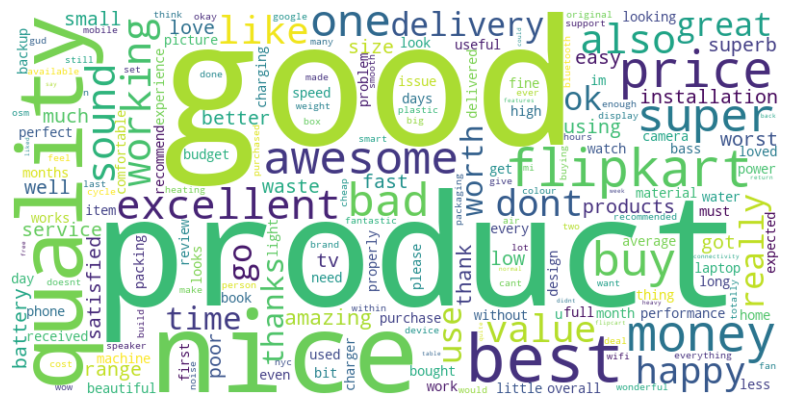

In [69]:
# Create a WordCloud
word_freq = Counter(filtered_words)
#print(word_freq)
wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(word_freq)
# Plotting the word cloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # Hide axes
plt.show()